#Longitudes de turno

Realizar un código para observar cuáles son las diferencias de longitud de turno por cada uno de los corpus. Dicho código deberá mostrar la **longitud por caracteres y palabras**.

Corpus:
- **c_espontaneo** (lenguaje espontáneo)
- **c_sintetico** (lenguaje sinténtico)
- **c_sintetico_all** (lenguaje sintetico sin filtrar)


Cargar el documento en cuestión (**c_sintetico.txt**).

In [ ]:
file_path = '/content/c_sintetico.txt'

with open(file_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()

# Optional: Remove newline characters from each line
lines = [line.strip() for line in lines]

print(f"Successfully read {len(lines)} lines from {file_path}")
# print first 5 lines to verify
# for i, line in enumerate(lines[:5]):
#     print(f"Line {i+1}: {line}")

Successfully read 171 lines from /content/c_sintetico.txt


Filtrar el corpus.

In [ ]:
import re

# Define the pattern: alphanumeric string (including accented characters) followed by ':' at the beginning of the line
# Updated pattern to include common Spanish accented characters (áéíóúÁÉÍÓÚüÜñÑ)
pattern = re.compile(r'^[\wáéíóúÁÉÍÓÚüÜñÑ.\s]+:')

# Initialize lists for filtered and removed lines
filtered_lines = []
removed_lines = []

# Iterate through the original lines and apply the filter
for line in lines:
    if pattern.match(line):
        filtered_lines.append(line)
    else:
        removed_lines.append(line)

print(f"Original number of lines: {len(lines)}")
print(f"Number of lines matching the pattern: {len(filtered_lines)}")
print(f"Number of lines removed: {len(removed_lines)}")

Original number of lines: 171
Number of lines matching the pattern: 81
Number of lines removed: 90


In [ ]:
filtered_lines

['Rodolfo: ¡Ay, Gladys, me siento como un reno en celo en una tienda de luces navideñas! Este lugar está más bonito que la villa de Santa Claus. Solo espero que el mesero no sea como el Grinch y nos traiga la cuenta antes de tiempo. Además, no quiero que me hagan caras porque pedí mi carne bien cocida, ya sabes que la sangre me da cosa, como si fuera un accidente navideño.',
 'José: ¡Ho ho ho! ¡Mira nada más quién viene por aquí! Si es mi querida Gladys y su ren... digo, novio. ¡Vaya sorpresa navideña! Pues fíjate que aquí estoy yo, listo para servirles un banquete digno del mismísimo Santa Claus. No te preocupes, Rodolfo, que aquí nadie te va a juzgar por querer tu carne tan cocida que parece que la pasó una avalancha del Polo Norte. ¿Y qué les traigo? ¿Unas empanadas para empezar, o prefieren ir directo al pavo... digo, al bife de chorizo?',
 'Gladys: ¡Ay, José, qué sorpresa verte aquí! Esto sí que es un regalo de Navidad inesperado, ¿eh? Rodolfo, amor, creo que deberíamos empezar co

Calculate the length of each line measured by characters (conversational turn):

In [ ]:
sum=0
sentencelength_char_sin = [] # Initialize the list
for l in filtered_lines:
  #missing: lenght measured by number of words
  #print (len(l))
  sum_char=sum+len(l) # This sum_char currently calculates the sum only for the current line's length due to sum=0 above.
  sentencelength_char_sin.append(len(l))

print(sentencelength_char_sin) # Print the final list outside the loop

[373, 473, 403, 492, 442, 419, 435, 449, 484, 153, 148, 147, 196, 145, 178, 173, 191, 169, 191, 211, 215, 307, 336, 325, 321, 309, 359, 287, 226, 276, 222, 238, 190, 325, 357, 380, 384, 412, 369, 273, 321, 299, 312, 331, 208, 259, 338, 346, 345, 369, 321, 291, 263, 260, 239, 260, 282, 188, 246, 173, 209, 309, 256, 211, 247, 233, 203, 250, 283, 223, 236, 241, 246, 272, 304, 244, 290, 272, 275, 278, 321]


Calculate the length of each line measured by words (conversational turn):

In [ ]:
sentencelength_words_sin = [] # Initialize the list to store word counts

for line in filtered_lines:
    # Split the line by spaces and punctuation, then filter out empty strings
    words = re.findall(r'\b\w+\b', line.lower()) # Use regex to find words, ignoring punctuation and converting to lowercase
    sentencelength_words_sin.append(len(words))

print(sentencelength_words_sin)

[72, 86, 70, 88, 85, 78, 76, 80, 89, 30, 27, 26, 35, 24, 33, 28, 32, 29, 32, 34, 38, 59, 63, 63, 55, 58, 64, 53, 36, 50, 38, 45, 34, 55, 65, 70, 72, 78, 72, 49, 64, 59, 57, 61, 38, 49, 63, 63, 64, 67, 55, 53, 49, 45, 43, 45, 53, 31, 41, 32, 34, 55, 44, 39, 42, 41, 38, 45, 53, 41, 38, 44, 45, 49, 54, 45, 52, 49, 49, 52, 55]


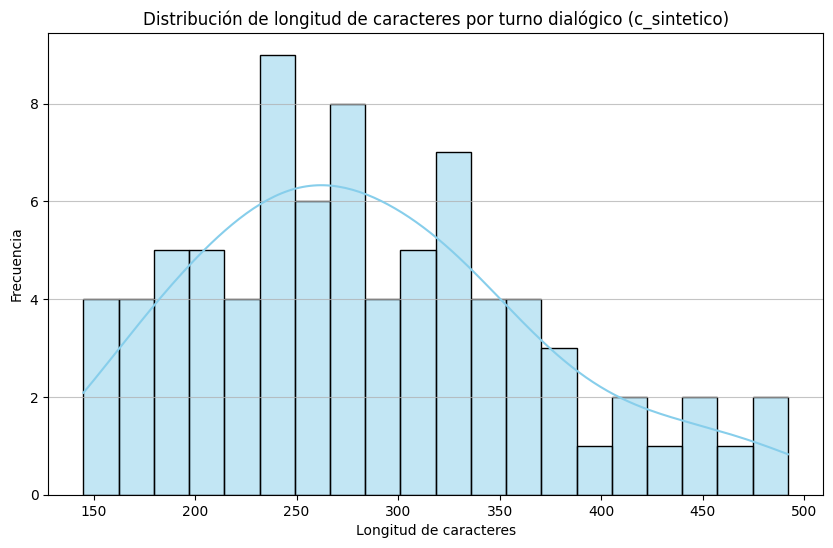

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the histogram
plt.figure(figsize=(10, 6))
sns.histplot(sentencelength_char_sin, bins=20, kde=True, color='skyblue')
plt.title('Distribución de longitud de caracteres por turno dialógico (c_sintetico)')
plt.xlabel('Longitud de caracteres')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()

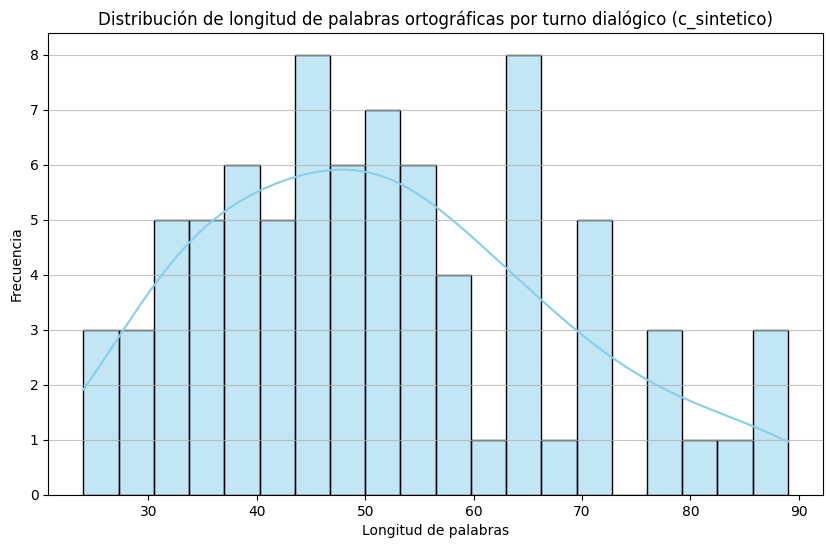

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the histogram
plt.figure(figsize=(10, 6))
sns.histplot(sentencelength_words_sin, bins=20, kde=True, color='skyblue')
plt.title('Distribución de longitud de palabras ortográficas por turno dialógico (c_sintetico)')
plt.xlabel('Longitud de palabras')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()



---


Cargar documento de diálogos espontáneos (**c_espontaneo.txt**).

In [ ]:
file_path = '/content/c_espontaneo.txt'

with open(file_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()

# Optional: Remove newline characters from each line
lines = [line.strip() for line in lines]

print(f"Successfully read {len(lines)} lines from {file_path}")

Successfully read 338 lines from /content/c_espontaneo.txt


In [ ]:
import re

# Define the pattern: alphanumeric string (including accented characters) followed by ':' at the beginning of the line
# Updated pattern to include common Spanish accented characters (áéíóúÁÉÍÓÚüÜñÑ)
pattern = re.compile(r'^[\wáéíóúÁÉÍÓÚüÜñÑ.\s]+:')

# Initialize lists for filtered and removed lines
filtered_lines = []
removed_lines = []

# Iterate through the original lines and apply the filter
for line in lines:
    if pattern.match(line):
        filtered_lines.append(line)
    else:
        removed_lines.append(line)

print(f"Original number of lines: {len(lines)}")
print(f"Number of lines matching the pattern: {len(filtered_lines)}")
print(f"Number of lines removed: {len(removed_lines)}")

Original number of lines: 338
Number of lines matching the pattern: 311
Number of lines removed: 27


In [ ]:
len(filtered_lines)

311

Calcula la longitud de caracteres de cada línea por turno conversacional.

In [ ]:
sum=0
sentencelength_char_esp = [] # Initialize the list
for l in filtered_lines:
  #missing: lenght measured by number of words
  #print (len(l))
  sum_char=sum+len(l) # This sum_char currently calculates the sum only for the current line's length due to sum=0 above.
  sentencelength_char_esp.append(len(l))

print(sentencelength_char_esp) # Print the final list outside the loop

[255, 31, 14, 75, 15, 20, 32, 30, 72, 22, 58, 45, 23, 83, 83, 98, 59, 21, 31, 52, 15, 25, 11, 40, 28, 12, 28, 12, 13, 25, 36, 45, 25, 27, 11, 12, 42, 11, 25, 30, 94, 62, 17, 97, 32, 34, 40, 27, 17, 17, 39, 11, 30, 42, 11, 13, 95, 24, 59, 26, 34, 42, 16, 9, 25, 23, 35, 31, 76, 56, 32, 28, 106, 32, 75, 34, 26, 16, 19, 27, 99, 27, 45, 19, 32, 29, 33, 14, 38, 19, 60, 20, 71, 18, 40, 34, 23, 47, 110, 110, 14, 16, 27, 17, 14, 48, 14, 12, 130, 16, 75, 128, 84, 79, 24, 50, 23, 32, 39, 63, 25, 86, 43, 49, 59, 53, 67, 138, 42, 39, 192, 73, 235, 70, 94, 61, 112, 12, 31, 13, 30, 20, 37, 91, 36, 105, 21, 125, 20, 17, 23, 45, 69, 14, 50, 45, 33, 12, 67, 17, 19, 32, 119, 19, 18, 34, 38, 49, 60, 71, 16, 29, 24, 62, 88, 240, 35, 55, 48, 54, 26, 31, 31, 27, 57, 26, 102, 33, 43, 98, 76, 13, 47, 20, 113, 79, 54, 33, 15, 14, 17, 17, 50, 50, 42, 117, 13, 28, 69, 46, 211, 607, 41, 62, 26, 114, 147, 11, 53, 14, 55, 19, 107, 289, 20, 325, 34, 77, 100, 159, 169, 17, 66, 103, 11, 103, 44, 127, 53, 445, 34, 29, 2

Calcula la longitud de palabras de cada línea por turno conversacional.

In [ ]:
sentencelength_words_esp = [] # Initialize the list to store word counts

for line in filtered_lines:
    # Split the line by spaces and punctuation, then filter out empty strings
    words = re.findall(r'\b\w+\b', line.lower()) # Use regex to find words, ignoring punctuation and converting to lowercase
    sentencelength_words_esp.append(len(words))

print(sentencelength_words_esp)

[41, 3, 2, 10, 2, 3, 5, 6, 11, 3, 10, 8, 4, 12, 15, 16, 10, 3, 5, 9, 3, 5, 2, 6, 5, 2, 4, 2, 2, 4, 6, 7, 4, 5, 2, 2, 8, 2, 5, 5, 17, 10, 3, 18, 6, 6, 5, 4, 2, 2, 4, 2, 6, 7, 2, 2, 19, 4, 10, 5, 5, 7, 3, 2, 4, 4, 6, 6, 14, 11, 6, 5, 19, 7, 12, 4, 4, 2, 3, 5, 16, 5, 8, 2, 6, 5, 6, 2, 6, 3, 9, 4, 11, 3, 8, 7, 4, 9, 21, 18, 3, 3, 5, 2, 3, 8, 3, 2, 26, 3, 14, 26, 14, 13, 5, 8, 3, 5, 8, 10, 4, 13, 8, 9, 10, 10, 13, 27, 7, 8, 34, 10, 48, 13, 18, 10, 22, 2, 5, 2, 5, 3, 8, 16, 7, 24, 4, 27, 3, 3, 3, 9, 12, 2, 8, 8, 4, 2, 13, 3, 4, 6, 21, 2, 2, 6, 5, 9, 10, 14, 2, 6, 4, 11, 19, 49, 6, 11, 8, 10, 4, 4, 6, 5, 10, 5, 19, 5, 6, 16, 11, 2, 9, 3, 19, 15, 9, 6, 2, 2, 3, 3, 11, 8, 9, 24, 2, 5, 12, 8, 32, 108, 6, 10, 4, 18, 26, 2, 10, 2, 9, 3, 22, 50, 2, 63, 5, 13, 18, 26, 34, 2, 9, 20, 2, 20, 8, 21, 11, 78, 4, 4, 3, 3, 5, 13, 10, 8, 8, 8, 2, 7, 8, 4, 3, 3, 3, 6, 25, 16, 8, 51, 3, 22, 5, 25, 37, 7, 3, 3, 2, 5, 4, 5, 5, 4, 3, 5, 4, 5, 23, 2, 5, 2, 23, 2, 2, 2, 3, 2, 5, 5, 27, 18, 9, 3, 8, 2, 17, 2, 3, 7, 

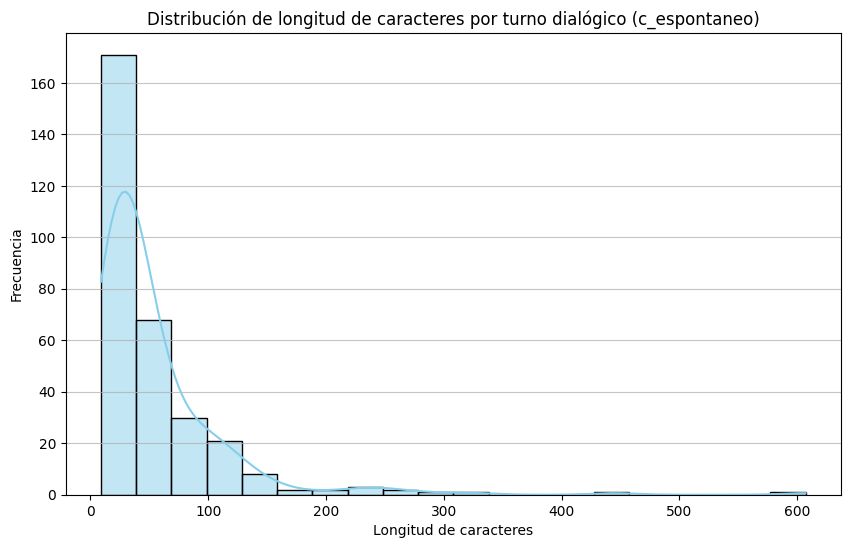

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the histogram
plt.figure(figsize=(10, 6))
sns.histplot(sentencelength_char_esp, bins=20, kde=True, color='skyblue')
plt.title('Distribución de longitud de caracteres por turno dialógico (c_espontaneo)')
plt.xlabel('Longitud de caracteres')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()

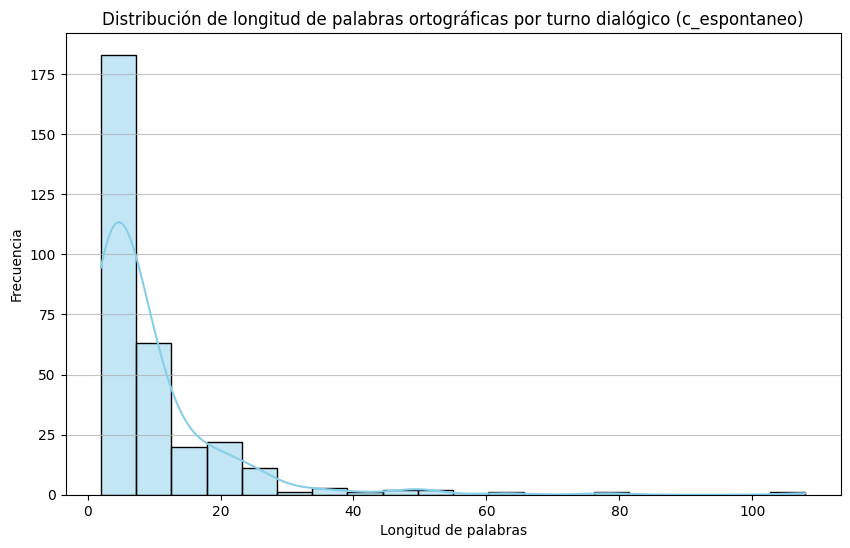

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the histogram
plt.figure(figsize=(10, 6))
sns.histplot(sentencelength_words_esp, bins=20, kde=True, color='skyblue')
plt.title('Distribución de longitud de palabras ortográficas por turno dialógico (c_espontaneo)')
plt.xlabel('Longitud de palabras')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()

#Comparación de distribuciones
##Comparación de distribuciones

Comparar únicamente los datos de los diálogos que fueron generados y se seleccionaron con los diálogos espontáneos.


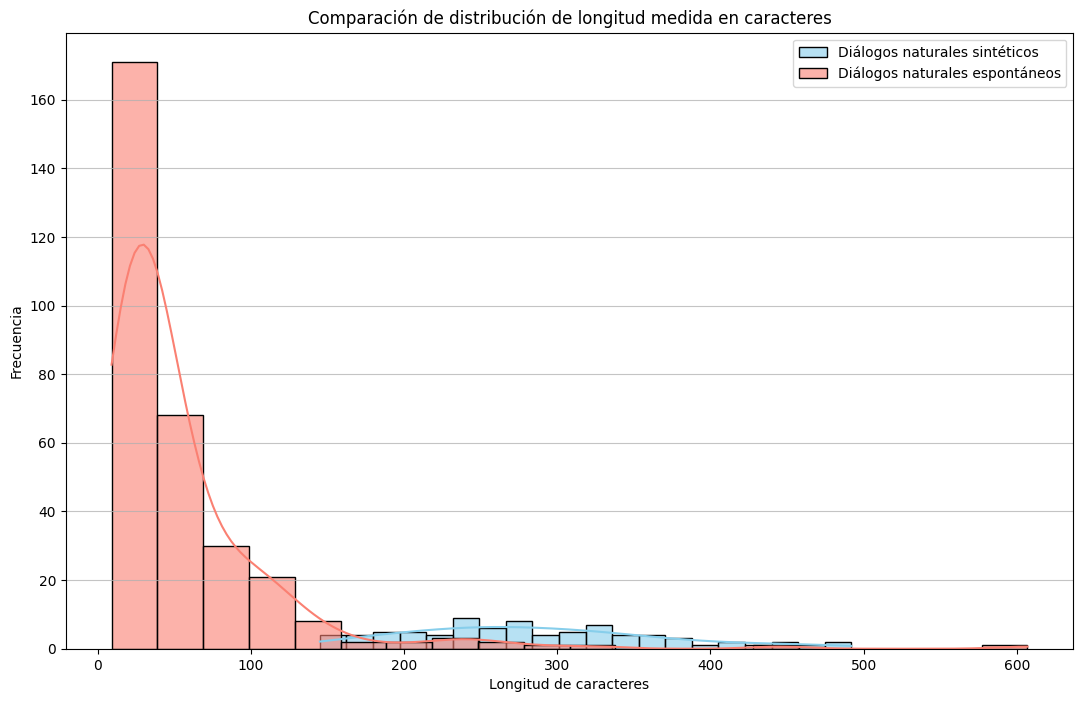

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crear el histograma para comparación
plt.figure(figsize=(13, 8))

# Histograma para diálogos sintéticos
sns.histplot(sentencelength_char_sin, bins=20, kde=True, color='skyblue', label='Diálogos naturales sintéticos', alpha=0.6)

# Histograma para diálogos espontáneos
sns.histplot(sentencelength_char_esp, bins=20, kde=True, color='salmon', label='Diálogos naturales espontáneos', alpha=0.6)

plt.title('Comparación de distribución de longitud medida en caracteres')
plt.xlabel('Longitud de caracteres')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

Comparar las distribuciones de longitud de palabras por turnos.

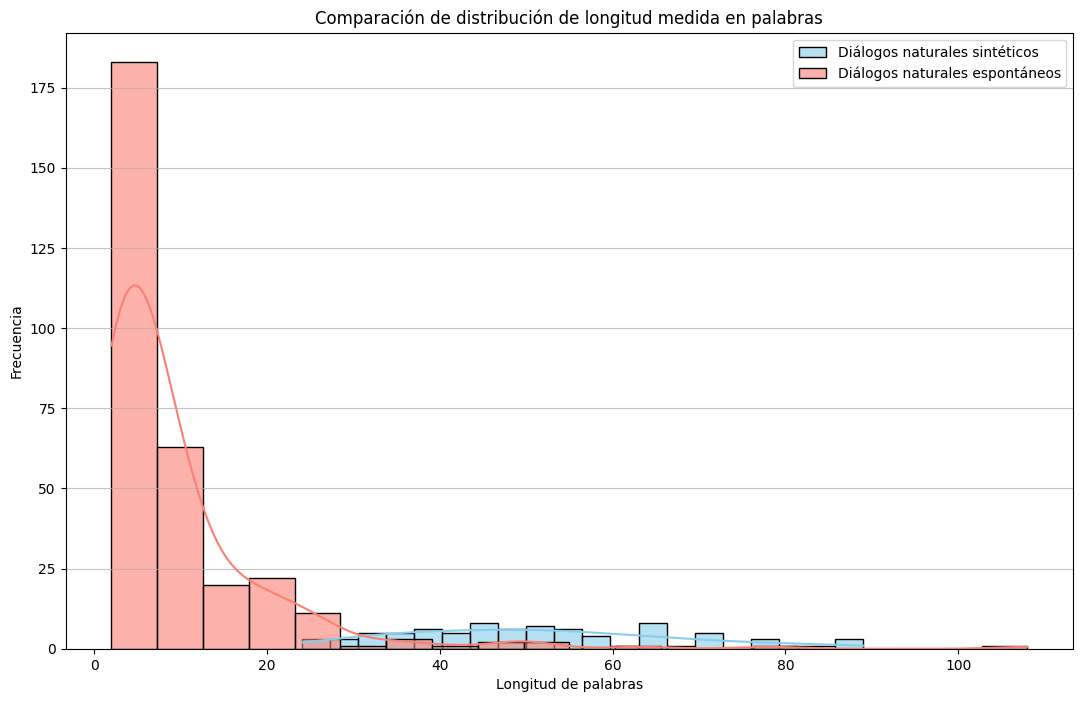

In [ ]:
# Crear el histograma para comparación
plt.figure(figsize=(13, 8))

# Histograma para diálogos sintéticos
sns.histplot(sentencelength_words_sin, bins=20, kde=True, color='skyblue', label='Diálogos naturales sintéticos', alpha=0.6)

# Histograma para diálogos espontáneos
sns.histplot(sentencelength_words_esp, bins=20, kde=True, color='salmon', label='Diálogos naturales espontáneos', alpha=0.6)

plt.title('Comparación de distribución de longitud medida en palabras')
plt.xlabel('Longitud de palabras')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()



---
**Corpus sintético (all)**


In [ ]:
file_path = '/content/c_sintetico_all.txt'

with open(file_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()

# Optional: Remove newline characters from each line
lines = [line.strip() for line in lines]

print(f"Successfully read {len(lines)} lines from {file_path}")

Successfully read 593 lines from /content/c_sintetico_all.txt


In [ ]:
import re

# Define the pattern: alphanumeric string (including accented characters) followed by ':' at the beginning of the line
# Updated pattern to include common Spanish accented characters (áéíóúÁÉÍÓÚüÜñÑ)
pattern = re.compile(r'^[\wáéíóúÁÉÍÓÚüÜñÑ.\s]+:')

# Initialize lists for filtered and removed lines
filtered_lines = []
removed_lines = []

# Iterate through the original lines and apply the filter
for line in lines:
    if pattern.match(line):
        filtered_lines.append(line)
    else:
        removed_lines.append(line)

print(f"Original number of lines: {len(lines)}")
print(f"Number of lines matching the pattern: {len(filtered_lines)}")
print(f"Number of lines removed: {len(removed_lines)}")

Original number of lines: 593
Number of lines matching the pattern: 507
Number of lines removed: 86


Calcula la longitud de cada línea medida por caracteres (turno conversacional)

In [ ]:
sum=0
sentencelength_char_all = [] # Initialize the list
for l in filtered_lines:
  #missing: lenght measured by number of words
  #print (len(l))
  sum_char=sum+len(l) # This sum_char currently calculates the sum only for the current line's length due to sum=0 above.
  sentencelength_char_all.append(len(l))

print(sentencelength_char_all) # Print the final list outside the loop

[275, 284, 249, 274, 279, 263, 253, 273, 267, 287, 248, 258, 257, 229, 263, 249, 256, 262, 243, 254, 244, 254, 254, 228, 363, 335, 370, 367, 386, 389, 364, 352, 444, 404, 438, 403, 416, 418, 418, 321, 315, 358, 355, 349, 308, 293, 287, 371, 419, 391, 396, 402, 342, 213, 214, 237, 280, 303, 270, 298, 339, 330, 249, 294, 300, 276, 286, 278, 447, 361, 314, 415, 348, 368, 413, 387, 367, 373, 321, 331, 248, 242, 214, 254, 202, 249, 280, 277, 245, 261, 292, 247, 383, 288, 227, 311, 351, 279, 319, 257, 267, 287, 302, 218, 224, 236, 241, 246, 272, 304, 244, 290, 272, 275, 278, 321, 297, 311, 386, 356, 402, 388, 376, 382, 375, 383, 399, 405, 170, 322, 308, 280, 270, 322, 283, 242, 287, 278, 246, 235, 214, 234, 187, 297, 237, 236, 275, 278, 347, 365, 370, 411, 142, 338, 274, 335, 342, 303, 294, 338, 290, 314, 316, 328, 358, 425, 430, 562, 474, 512, 547, 528, 511, 547, 511, 470, 188, 238, 244, 295, 279, 257, 278, 287, 276, 335, 243, 298, 185, 159, 218, 206, 275, 194, 167, 159, 255, 221, 240, 197,

Calcula la longitud de cada línea medida por palabras (turno conversacional)

In [ ]:
sentencelength_words_all = [] # Initialize the list to store word counts

for line in filtered_lines:
    # Split the line by spaces and punctuation, then filter out empty strings
    words = re.findall(r'\b\w+\b', line.lower()) # Use regex to find words, ignoring punctuation and converting to lowercase
    sentencelength_words_all.append(len(words))

print(sentencelength_words_all)

[48, 49, 47, 46, 50, 51, 42, 46, 51, 47, 44, 44, 47, 45, 46, 48, 49, 48, 46, 46, 49, 45, 48, 39, 60, 61, 66, 63, 63, 68, 59, 59, 74, 73, 74, 72, 79, 72, 67, 59, 52, 64, 64, 64, 53, 50, 52, 64, 74, 72, 68, 68, 61, 39, 39, 40, 45, 50, 48, 53, 64, 59, 46, 53, 54, 48, 52, 52, 72, 65, 55, 70, 61, 66, 72, 68, 61, 61, 52, 62, 41, 42, 34, 47, 34, 42, 50, 50, 43, 46, 56, 44, 66, 53, 41, 56, 64, 49, 58, 41, 45, 53, 55, 44, 41, 38, 44, 45, 49, 54, 45, 52, 49, 49, 52, 55, 52, 55, 67, 60, 69, 68, 66, 67, 63, 67, 70, 71, 28, 52, 53, 51, 45, 61, 51, 44, 50, 50, 38, 40, 35, 37, 34, 54, 42, 44, 46, 48, 59, 64, 60, 71, 27, 54, 51, 60, 64, 51, 52, 57, 50, 58, 54, 57, 64, 74, 78, 96, 80, 84, 100, 94, 87, 96, 87, 85, 32, 44, 42, 52, 50, 49, 52, 50, 48, 58, 47, 58, 34, 32, 39, 39, 49, 35, 28, 32, 43, 39, 46, 33, 41, 33, 43, 40, 39, 56, 52, 69, 47, 51, 53, 54, 43, 34, 41, 48, 50, 47, 48, 48, 52, 64, 68, 54, 31, 42, 32, 34, 55, 44, 39, 42, 41, 38, 45, 53, 60, 67, 69, 69, 65, 67, 65, 57, 37, 49, 65, 69, 54, 71

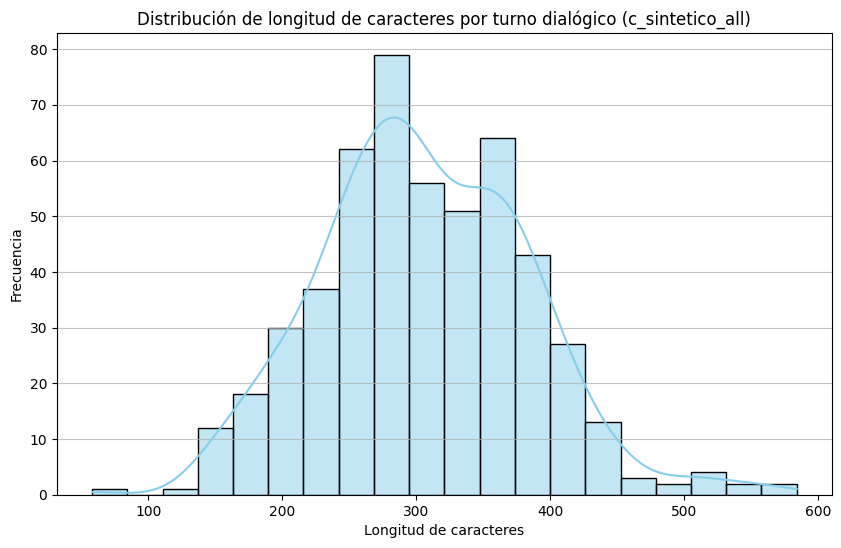

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the histogram
plt.figure(figsize=(10, 6))
sns.histplot(sentencelength_char_all, bins=20, kde=True, color='skyblue')
plt.title('Distribución de longitud de caracteres por turno dialógico (c_sintetico_all)')
plt.xlabel('Longitud de caracteres')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()

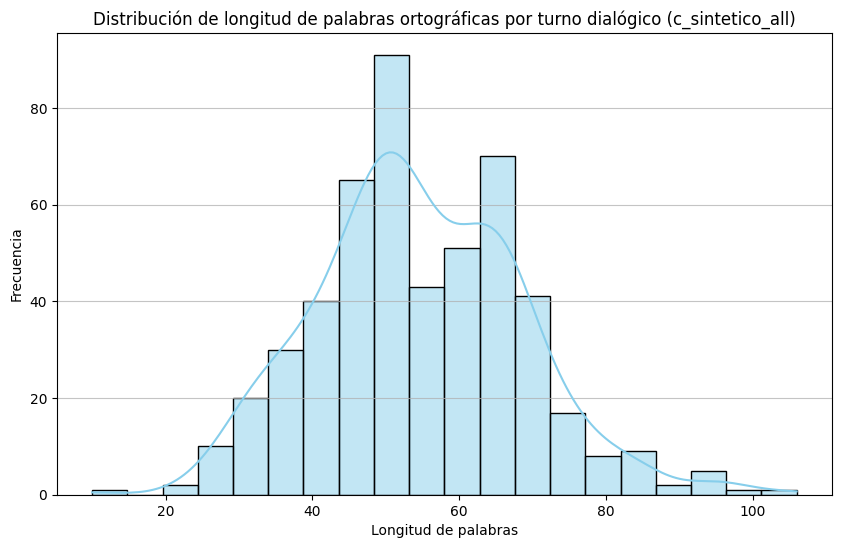

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the histogram
plt.figure(figsize=(10, 6))
sns.histplot(sentencelength_words_all, bins=20, kde=True, color='skyblue')
plt.title('Distribución de longitud de palabras ortográficas por turno dialógico (c_sintetico_all)')
plt.xlabel('Longitud de palabras')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()

##Comparar los datos de los diálogos sintéticos que fueron filtrados con aquellos diálogos que no fueron filtrados.

**Comparación de diálogos sintéticos (c_sintetico y c_sintetico_all)**

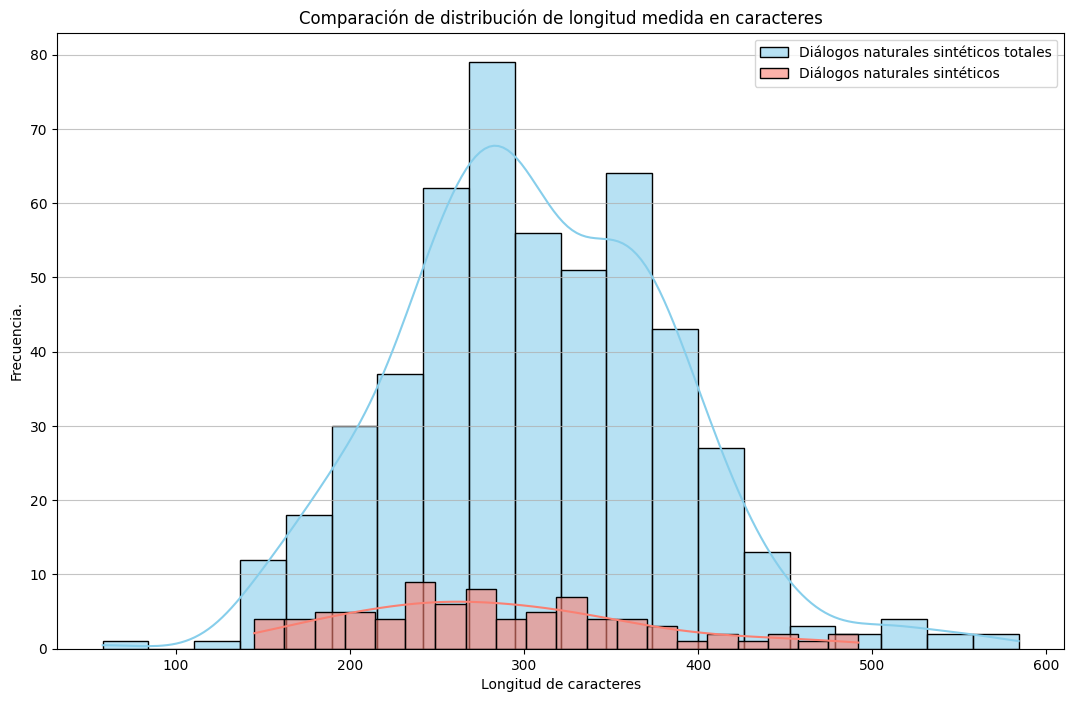

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crear el histograma para comparación
plt.figure(figsize=(13, 8))

# Histograma para diálogos sintéticos_all
sns.histplot(sentencelength_char_all, bins=20, kde=True, color='skyblue', label='Diálogos naturales sintéticos totales', alpha=0.6)

# Histograma para los diálogos sinténticos
sns.histplot(sentencelength_char_sin, bins=20, kde=True, color='salmon', label='Diálogos naturales sintéticos', alpha=0.6)

plt.title('Comparación de distribución de longitud medida en caracteres')
plt.xlabel('Longitud de caracteres')
plt.ylabel('Frecuencia.')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

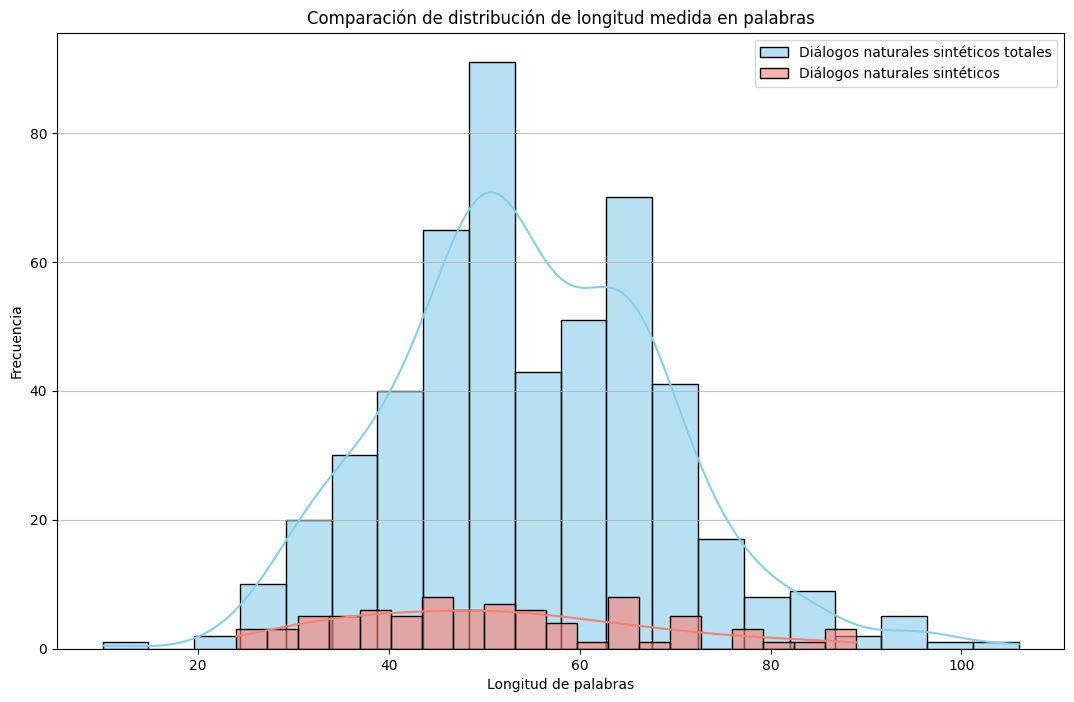

In [ ]:
# Crear el histograma para comparación
plt.figure(figsize=(13, 8))

# Histograma para diálogos sintéticos_all
sns.histplot(sentencelength_words_all, bins=20, kde=True, color='skyblue', label='Diálogos naturales sintéticos totales', alpha=0.6)

# Histograma para diálogos sintenticos
sns.histplot(sentencelength_words_sin, bins=20, kde=True, color='salmon', label='Diálogos naturales sintéticos', alpha=0.6)

plt.title('Comparación de distribución de longitud medida en palabras')
plt.xlabel('Longitud de palabras')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

**Comparación de espontáneo y sintético all:**

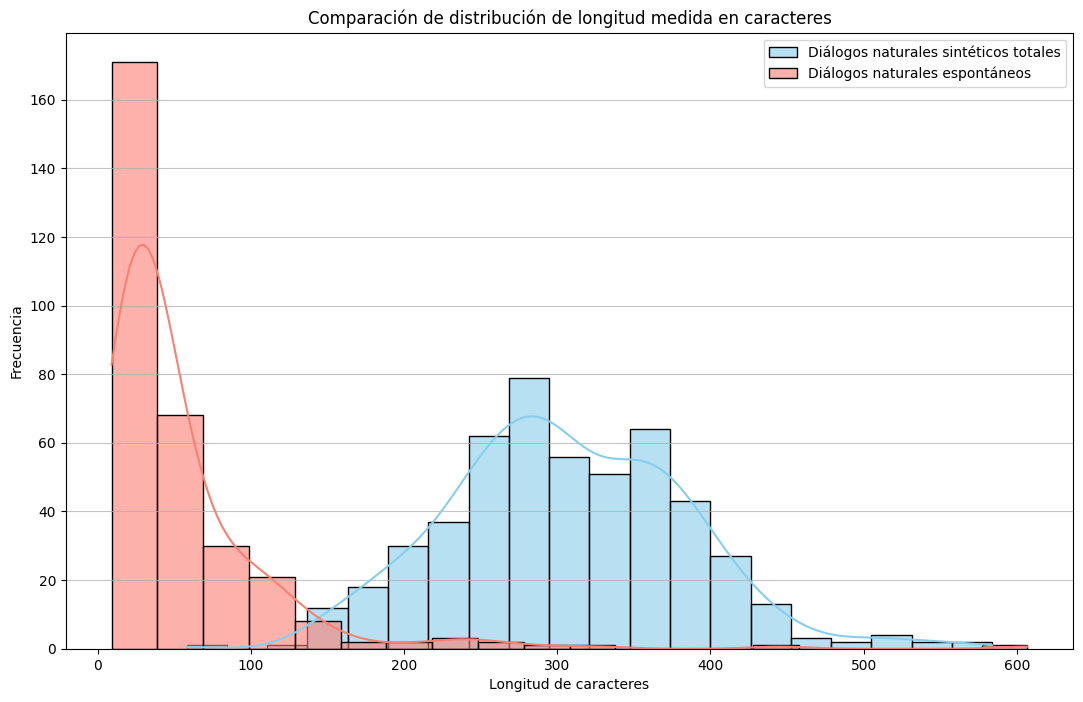

In [ ]:
# Crear el histograma para comparación
plt.figure(figsize=(13, 8))

# Histograma para diálogos sintéticos_all
sns.histplot(sentencelength_char_all, bins=20, kde=True, color='skyblue', label='Diálogos naturales sintéticos totales', alpha=0.6)

# Histograma para los diálogos sinténticos
sns.histplot(sentencelength_char_esp, bins=20, kde=True, color='salmon', label='Diálogos naturales espontáneos', alpha=0.6)

plt.title('Comparación de distribución de longitud medida en caracteres')
plt.xlabel('Longitud de caracteres')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

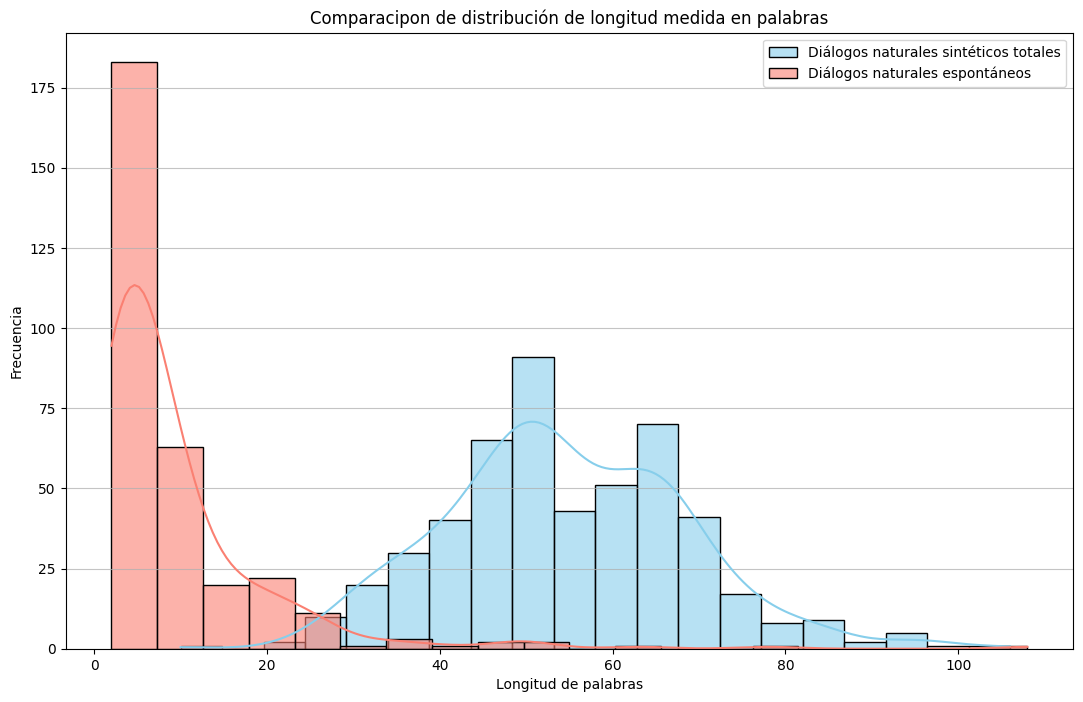

In [ ]:
# Crear el histograma para comparación
plt.figure(figsize=(13, 8))

# Histograma para diálogos sintéticos_all
sns.histplot(sentencelength_words_all, bins=20, kde=True, color='skyblue', label='Diálogos naturales sintéticos totales', alpha=0.6)

# Histograma para diálogos sintenticos
sns.histplot(sentencelength_words_esp, bins=20, kde=True, color='salmon', label='Diálogos naturales espontáneos', alpha=0.6)

plt.title('Comparacipon de distribución de longitud medida en palabras')
plt.xlabel('Longitud de palabras')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()



---
**Promedios de longitudes**



In [ ]:
import statistics

print("avg. char length (synthetic):", statistics.mean(sentencelength_char_sin))
print("avg. char length (synthetic-all):", statistics.mean(sentencelength_char_all))
print("avg. char length (spontaneous):", statistics.mean(sentencelength_char_esp))
print("")
print("avg. word length (synthetic):", statistics.mean(sentencelength_words_sin))
print("avg. word length (synthetic-all):", statistics.mean(sentencelength_words_all))
print("avg. word length (spontaneous):", statistics.mean(sentencelength_words_esp))
print("")
print("median char length (synthetic):", statistics.median(sentencelength_char_sin))
print("median char length (synthetic-all):", statistics.median(sentencelength_char_all))
print("median char length (spontaneous):", statistics.median(sentencelength_char_esp))
print("")
print("median word length (synthetic):", statistics.median(sentencelength_words_sin))
print("median word length (synthetic-all):", statistics.median(sentencelength_words_all))
print("median word length (spontaneous):", statistics.median(sentencelength_words_esp))


avg. char length (synthetic): 284.4074074074074
avg. char length (synthetic-all): 306.07100591715977
avg. char length (spontaneous): 54.440514469453376

avg. word length (synthetic): 51.44444444444444
avg. word length (synthetic-all): 54.548323471400394
avg. word length (spontaneous): 9.42443729903537

median char length (synthetic): 275
median char length (synthetic-all): 300
median char length (spontaneous): 34

median word length (synthetic): 49
median word length (synthetic-all): 53
median word length (spontaneous): 6
